In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


def convert_float32_to_uint8(img):
    return np.round((img * 255.0).clip(0, 255)).astype(np.uint8)


dim_img = cv2.imread("./dim.png")
sensor_img = cv2.imread("./sensor16.png")

dim_height, dim_width = dim_img.shape[:2]

print(f"Dim dimensions: {dim_height}px x {dim_width}px")

assert dim_width > dim_height

print(f"Data type for the dim image: {dim_img.dtype}")

dim_blue, dim_green, dim_red = dim_img.transpose(2, 0, 1)

print(f"""Dim image (min-max for each channel):
    Blue Channel: Min: {dim_blue.min()}. Max: {dim_blue.max()}
    Green Channel: Min: {dim_green.min()}. Max: {dim_green.max()}
    Red Channel: Min: {dim_red.min()}. Max: {dim_red.max()}""")

Dim dimensions: 320px x 480px
Data type for the dim image: uint8
Dim image (min-max for each channel):
    Blue Channel: Min: 25. Max: 114
    Green Channel: Min: 25. Max: 114
    Red Channel: Min: 25. Max: 114


Wrong pixels: 53872
Percentage wrong: 35.07%


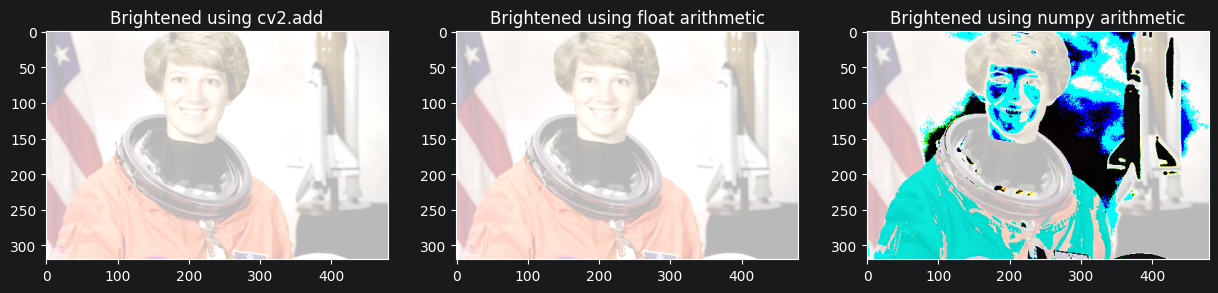

In [2]:
brighten_k = 160

# Brightening with CV2
cv_brighten = cv2.add(dim_img.copy(), brighten_k)

# Brighten with the float approach
float_brighten = np.round(
        (dim_img.astype(np.float32) + 160).clip(0, 255)
).astype(np.uint8)

# Numpy brighten (expect wraparounds)
numpy_brighten = dim_img.copy() + brighten_k

assert np.array_equal(float_brighten, cv_brighten)

# Compare pixels
diff = numpy_brighten != float_brighten
pixel_diff = np.any(diff, axis=2)

wrong_pixels = pixel_diff.sum()
total_pixels = dim_height * dim_width
percentage_wrong = (wrong_pixels / total_pixels) * 100

print(f"Wrong pixels: {wrong_pixels}")
print(f"Percentage wrong: {percentage_wrong:.2f}%")

# Display in RGB
fig, (plt_1, plt_2, plt_3) = plt.subplots(1, 3, figsize=(15, 5))

plt_1.imshow(cv_brighten.copy()[:, :, ::-1])
plt_1.set_title("Brightened using cv2.add")

plt_2.imshow(float_brighten.copy()[:, :, ::-1])
plt_2.set_title("Brightened using float arithmetic")

plt_3.imshow(numpy_brighten.copy()[:, :, ::-1])
plt_3.set_title("Brightened using numpy arithmetic")

plt.show()

In [3]:
float_dim = (dim_img / 255.0).astype(np.float32)

assert float_dim.dtype == np.float32
assert float_dim.min() >= 0
assert float_dim.max() <= 1

int_dim = convert_float32_to_uint8(float_dim)

assert np.array_equal(dim_img, int_dim)

In [4]:
# Min-max stretching (normalization)
img_min = float_dim.min()
img_max = float_dim.max()

man_normalized = ((float_dim - img_min) / (img_max - img_min)) * 255
man_normalized = np.round(man_normalized) / 255
man_normalized_int = convert_float32_to_uint8(man_normalized)

cv2_normalized = cv2.normalize(dim_img, None, 0, 255, cv2.NORM_MINMAX)
cv2_normalized_float = (cv2_normalized / 255.0).astype(np.float32)

normalized_diff = np.abs(cv2_normalized_float - man_normalized)

assert normalized_diff.max() <= 1

In [5]:
## ImageNet returns data in RGB, so we'd need to convert cv2_normalized to RGB
float_dim_rgb = float_dim.copy()[:, :, ::-1]

# Standardization with Image Net
imgnet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
imgnet_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

dim_standrd_imgnet = (float_dim_rgb - imgnet_mean) / imgnet_std

print(f"""Image standardized with ImageNet statistics:
    Minimum: {dim_standrd_imgnet.min()}
    Maximum: {dim_standrd_imgnet.max()}
    dtype: {dim_standrd_imgnet.dtype}""")

## Standardization with per-channel mean and standard deviation
channel_mean = float_dim_rgb.mean(axis=(0, 1))
channel_std = float_dim_rgb.std(axis=(0, 1))

dim_standrd_computed = (float_dim_rgb - channel_mean) / channel_std

print(f"""Image standardized with per-channel statistics:
    Minimum: {dim_standrd_computed.min()}
    Maximum: {dim_standrd_computed.max()}
    dtype: {dim_standrd_computed.dtype}""")

assert np.allclose(dim_standrd_computed.mean(axis=(0, 1)), 0, atol=1e-2)
assert np.allclose(dim_standrd_computed.std(axis=(0, 1)), 1, atol=1e-2)

Image standardized with ImageNet statistics:
    Minimum: -1.689785122871399
    Maximum: 0.1824837327003479
    dtype: float32
Image standardized with per-channel statistics:
    Minimum: -1.9820947647094727
    Maximum: 1.9348751306533813
    dtype: float32


In [6]:
## sensor 16
sensor_16 = cv2.imread("./sensor16.png")
sensor_16_unchanged = cv2.imread("./sensor16.png", cv2.IMREAD_UNCHANGED)

print(f"""Sensor 16 details
    Shape: {sensor_16.shape}
    dtype: {sensor_16.dtype}
    Max: {sensor_16.max()}
""")

print(f"""Sensor 16 with `IMREAD_UNCHANGED` details
    Shape: {sensor_16_unchanged.shape}
    dtype: {sensor_16_unchanged.dtype}
    Max: {sensor_16_unchanged.max()}
""")

ii16 = np.iinfo(np.uint16)
normalized_16_bit = sensor_16_unchanged.astype(np.float32) / ii16.max

assert normalized_16_bit.max() <= 1

Sensor 16 details
    Shape: (240, 400, 3)
    dtype: uint8
    Max: 255

Sensor 16 with `IMREAD_UNCHANGED` details
    Shape: (240, 400)
    dtype: uint16
    Max: 65535



Plain `cv2.imread()` discarded the image’s 16-bit intensity precision by loading it as 8-bit data.